# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Habibullah**
- **Student ID: 023-24-0077**
- **Section: D**
- **GitHub:** https://github.com/Habibullah-Gabol/machine-learning-lab
- **Kaggle:**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

df.drop("customerID", axis=1, inplace=True)

print("\nCleaned Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

X = df.drop("Churn", axis=1)
y = df["Churn"]

categorical_features = X.select_dtypes(
    include=["object"]
).columns

X = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

print("\nEncoding Completed Successfully!")

Training Features Shape: (5634, 30)
Testing Features Shape: (1409, 30)

Training Target Distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64

Encoding Completed Successfully!


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# YOUR CODE HERE — unscaled linear SVM

from sklearn.exceptions import ConvergenceWarning

svm_raw = SVC(kernel='linear', random_state=42)

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")

    start_time = time.time()
    svm_raw.fit(X_train, y_train)
    raw_time = time.time() - start_time

    raw_warnings = [
        warning for warning in w
        if issubclass(warning.category, ConvergenceWarning)
    ]

y_pred_raw = svm_raw.predict(X_test)

raw_accuracy = accuracy_score(y_test, y_pred_raw)
raw_f1 = f1_score(y_test, y_pred_raw)

print("Unscaled Linear SVM")
print("Accuracy:", raw_accuracy)
print("F1-Score:", raw_f1)
print("Training Time:", raw_time, "seconds")
print("Convergence Warnings:", len(raw_warnings))

Unscaled Linear SVM
Accuracy: 0.7920511000709723
F1-Score: 0.5266558966074314
Training Time: 316.50159072875977 seconds
Convergence Warnings: 0


In [4]:
# YOUR CODE HERE — scaled linear SVM

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

svm_scaled = SVC(kernel='linear', random_state=42)

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")

    start_time = time.time()
    svm_scaled.fit(X_train_s, y_train)
    scaled_time = time.time() - start_time

    scaled_warnings = [
        warning for warning in w
        if issubclass(warning.category, ConvergenceWarning)
    ]

y_pred_scaled = svm_scaled.predict(X_test_s)

scaled_accuracy = accuracy_score(y_test, y_pred_scaled)
scaled_f1 = f1_score(y_test, y_pred_scaled)

print("Scaled Linear SVM")
print("Accuracy:", scaled_accuracy)
print("F1-Score:", scaled_f1)
print("Training Time:", scaled_time, "seconds")
print("Convergence Warnings:", len(scaled_warnings))

Scaled Linear SVM
Accuracy: 0.7892122072391767
F1-Score: 0.5714285714285714
Training Time: 0.8568031787872314 seconds
Convergence Warnings: 0


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The unscaled model achieved 79.21% accuracy and 52.67% F1-score, while the scaled model achieved 78.92% accuracy and 57.14% F1-score. The scaled model performed better in terms of F1-score. Its training time was approximately 0.86 seconds compared to 316.50 seconds for the unscaled model. Neither model produced convergence warnings. Therefore, feature scaling significantly improved training efficiency and F1-score.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*SVM is a distance-based algorithm that calculates margins and decision boundaries using feature values. When features have different scales, features with larger numerical ranges can dominate the distance calculations. This can negatively affect the decision boundary and make training computationally expensive. StandardScaler brings features to a comparable scale, allowing SVM to learn a more balanced decision boundary efficiently.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use the scaled version for all subsequent SVM experiments because it achieved a higher F1-score and significantly reduced training time. Scaling also ensures that features contribute more fairly to the distance calculations.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics

kernels = ['linear', 'rbf', 'poly']

kernel_results = []
kernel_models = {}

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)

    start_time = time.time()
    model.fit(X_train_s, y_train)
    training_time = time.time() - start_time

    y_pred = model.predict(X_test_s)

    kernel_models[kernel] = model

    kernel_results.append({
        'Kernel': kernel,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'Support Vectors': model.support_.shape[0],
        'Training Time': training_time
    })

print("Kernel Training Completed!")

Kernel Training Completed!


In [6]:
# YOUR CODE HERE — comparison table

kernel_df = pd.DataFrame(kernel_results)

display(
    kernel_df.sort_values(
        by='F1-Score',
        ascending=False
    ).reset_index(drop=True)
)

,Kernel,Accuracy,Precision,Recall,F1-Score,Support Vectors,Training Time
0,linear,0.789212,0.620690,0.529412,0.571429,2569,1.334616
1,rbf,0.792761,0.644366,0.489305,0.556231,2661,1.145545
2,poly,0.789212,0.642066,0.465241,0.539535,2739,0.835561


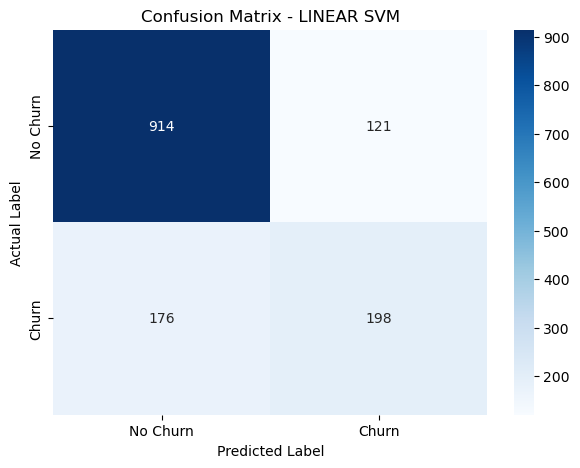

In [7]:
# YOUR CODE HERE — confusion matrix for the best kernel

best_kernel = kernel_df.loc[
    kernel_df['F1-Score'].idxmax(),
    'Kernel'
]

best_kernel_model = kernel_models[best_kernel]

y_pred_best = best_kernel_model.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title(f'Confusion Matrix - {best_kernel.upper()} SVM')
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* Linear SVM produced the best F1-score of 57.14%, followed by RBF with 55.62% and Polynomial with 53.95%. This is somewhat surprising because RBF can learn nonlinear decision boundaries and is generally more flexible than a linear kernel. However, the results show that a simpler linear decision boundary performed better on this dataset.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* Polynomial SVM used the most support vectors, with 2,739, followed by RBF with 2,661 and Linear with 2,569. A higher number of support vectors indicates that more training observations contribute to defining the decision boundary. It can suggest a more complicated boundary or more observations near the margin, although the count alone does not prove greater model complexity.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* I would carry forward the RBF kernel for hyperparameter tuning because it can learn nonlinear decision boundaries and achieved the highest accuracy of 79.28% and precision of 64.44%. Although Linear SVM achieved a higher F1-score of 57.14% compared to RBF's 55.62%, RBF is worth tuning to investigate whether its performance can be improved through optimizing C and gamma.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_s)

print("Original Features:", X_train_s.shape[1])
print("Reduced Features:", X_train_pca.shape[1])

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", sum(pca.explained_variance_ratio_))

Original Features: 30
Reduced Features: 2
Explained Variance Ratio: [0.33246151 0.11980321]
Total Explained Variance: 0.45226472427671316


In [9]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection

C_values = [0.01, 1, 100]

pca_models = {}

for c in C_values:
    model = SVC(kernel='rbf', C=c, gamma='scale', random_state=42)
    model.fit(X_train_pca, y_train)

    pca_models[c] = model

    print(
        f"C = {c}, Support Vectors = {model.support_.shape[0]}"
    )

C = 0.01, Support Vectors = 2997
C = 1, Support Vectors = 2659
C = 100, Support Vectors = 2631


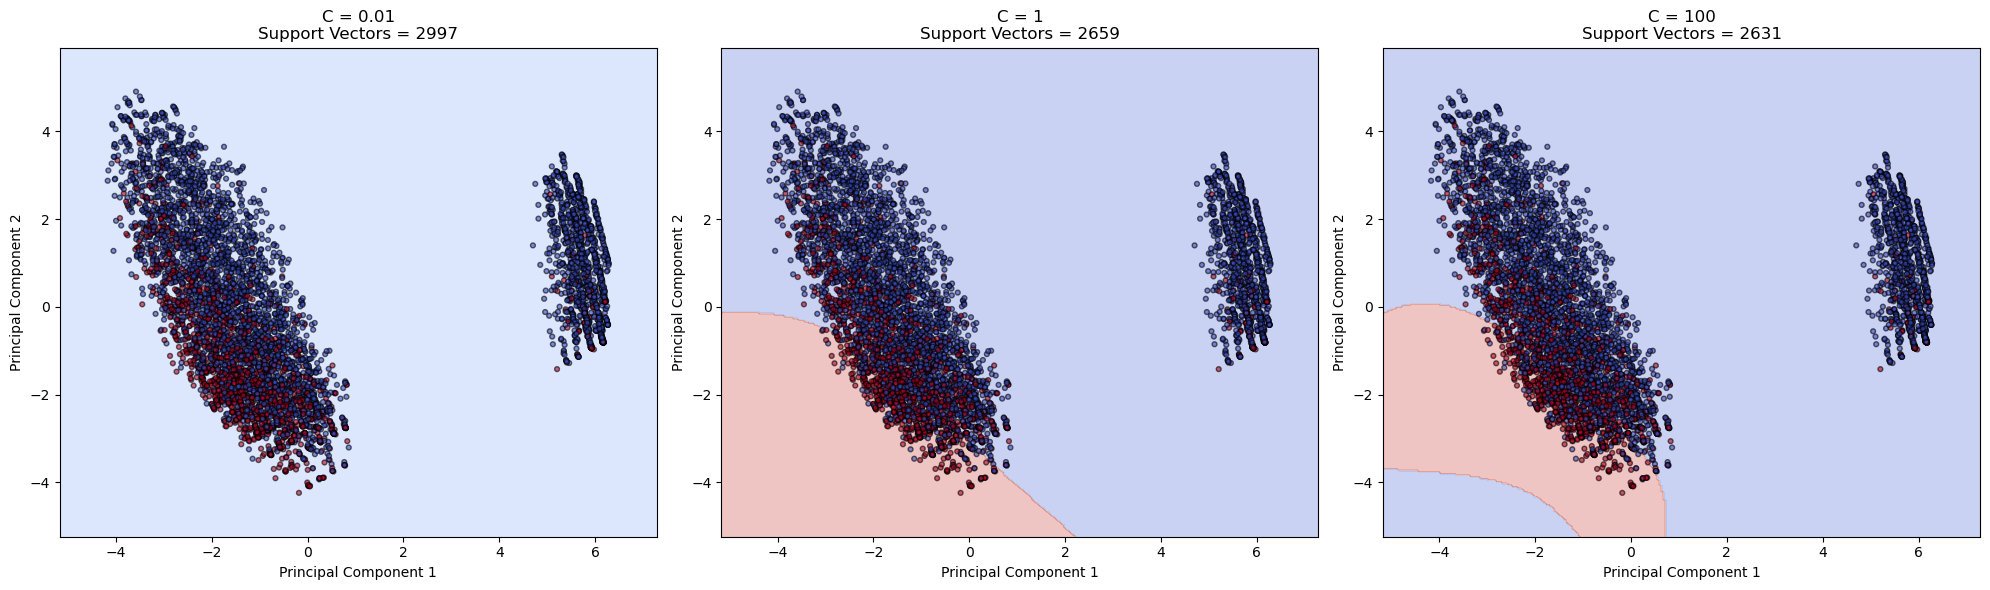

In [10]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, c in zip(axes, C_values):
    model = pca_models[c]

    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    ax.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap='coolwarm',
        edgecolors='k',
        s=12,
        alpha=0.6
    )

    ax.set_title(
        f'C = {c}\nSupport Vectors = {model.support_.shape[0]}'
    )

    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* When C is 0.01, the decision boundary is very simple and predicts almost the entire region as one class, indicating underfitting. At C = 1, the model creates a more defined nonlinear decision boundary. At C = 100, the boundary changes further to classify training observations more strictly. Increasing C increases the penalty for misclassification and allows the model to fit the training data more closely.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* The number of support vectors decreases as C increases. At C = 0.01, there are 2,997 support vectors; at C = 1, there are 2,659; and at C = 100, there are 2,631. This is consistent with the idea that a larger C penalizes margin violations more strongly, allowing fewer training observations to remain within or beyond the margin.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C = 0.01 appears to be underfitting because its decision boundary is too simple and fails to separate the two classes effectively. C = 100 is the strongest candidate for overfitting because it places greater emphasis on correctly classifying training observations. However, the plot alone cannot conclusively establish overfitting; test-set performance would be needed for confirmation.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The original dataset contains 30 features, but PCA reduces them to only two dimensions, preserving approximately 45.23% of the variance. Therefore, some information is lost during dimensionality reduction. The resulting decision boundary is learned using only the two principal components and does not represent the actual 30-dimensional decision boundary. It may therefore give a misleading impression of the model's real classification performance and complexity.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
# YOUR CODE HERE — define param_grid and run GridSearchCV

from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1]
}

svm_rbf = SVC(kernel='rbf', random_state=42)

gs = GridSearchCV(
    estimator=svm_rbf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=2,
    verbose=1
)

start_time = time.time()

gs.fit(X_train_s, y_train)

grid_search_time = time.time() - start_time

print("Grid Search Completed!")
print("Best Parameters:", gs.best_params_)
print("Best Cross-Validation F1-Score:", gs.best_score_)
print("Total Training Time:", grid_search_time, "seconds")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Grid Search Completed!
Best Parameters: {'C': 100, 'gamma': 0.01}
Best Cross-Validation F1-Score: 0.5876873460047569
Total Training Time: 53.46099376678467 seconds


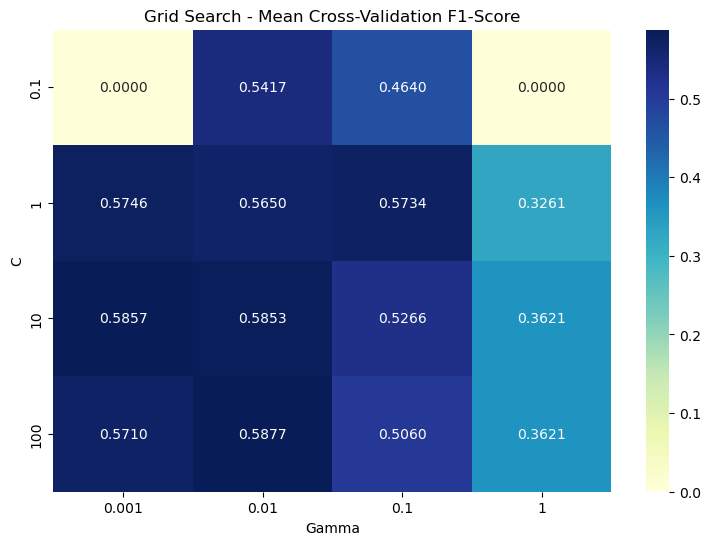

In [12]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid

results = pd.DataFrame(gs.cv_results_)

C_values = param_grid['C']
gamma_values = param_grid['gamma']

score_matrix = results['mean_test_score'].values.reshape(
    len(C_values),
    len(gamma_values)
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    score_matrix,
    annot=True,
    fmt='.4f',
    cmap='YlGnBu',
    xticklabels=gamma_values,
    yticklabels=C_values
)

plt.xlabel('Gamma')
plt.ylabel('C')
plt.title('Grid Search - Mean Cross-Validation F1-Score')
plt.show()

Best SVM Model Performance
Best Parameters: {'C': 100, 'gamma': 0.01}
Accuracy: 0.7785663591199432
Precision: 0.593939393939394
Recall: 0.5240641711229946
F1-Score: 0.5568181818181818


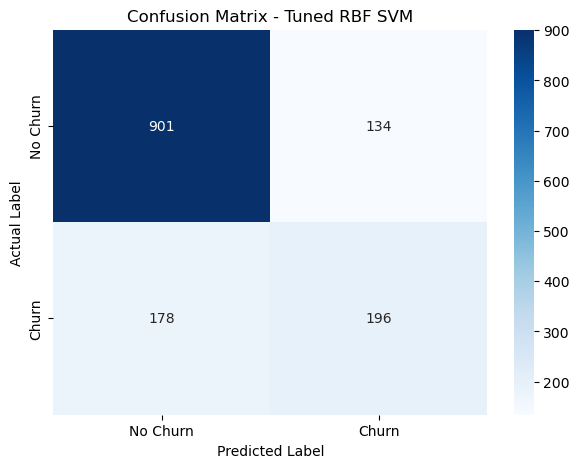

In [13]:
# YOUR CODE HERE — refit best estimator, evaluate on test set

best_svm = gs.best_estimator_

y_pred_svm = best_svm.predict(X_test_s)

print("Best SVM Model Performance")
print("Best Parameters:", gs.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1-Score:", f1_score(y_test, y_pred_svm))

cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Tuned RBF SVM')
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* GridSearchCV identified C = 100 and gamma = 0.01 as the best hyperparameter combination. The corresponding mean cross-validated F1-score was 0.5877 (58.77%).

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* The heatmap shows that several combinations perform similarly. For example, C = 10 and gamma = 0.001 achieved an F1-score of 0.5857, while C = 100 and gamma = 0.01 achieved 0.5877. This indicates that the model performs reasonably well across a small region of hyperparameter combinations rather than depending entirely on one exact combination.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* The cross-validated F1-score was 58.77%, while the final test-set F1-score was 55.68%. There was a difference of approximately 3.09 percentage points. This indicates a small performance gap between cross-validation and test evaluation. A large gap could suggest overfitting or poor generalization to unseen data.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* The untuned RBF model achieved an F1-score of 55.62%, whereas the tuned RBF model achieved 55.68%. The improvement was approximately 0.06 percentage points. Therefore, hyperparameter tuning produced only a marginal improvement in test performance, although it helped identify the best configuration through systematic cross-validation.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [14]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison

best_C = gs.best_params_['C']
best_gamma = gs.best_params_['gamma']

svm_default = SVC(
    kernel='rbf',
    C=best_C,
    gamma=best_gamma,
    class_weight=None,
    probability=True,
    random_state=42
)

svm_balanced = SVC(
    kernel='rbf',
    C=best_C,
    gamma=best_gamma,
    class_weight='balanced',
    probability=True,
    random_state=42
)

models = {
    'Normal SVM': svm_default,
    'Balanced SVM': svm_balanced
}

imbalance_results = []
imbalance_predictions = {}

for name, model in models.items():

    model.fit(X_train_s, y_train)

    y_pred = model.predict(X_test_s)

    imbalance_predictions[name] = y_pred

    imbalance_results.append({
        'Model': name,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

    print("\n", name)
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1-Score:", f1_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

imbalance_df = pd.DataFrame(imbalance_results)

display(imbalance_df)


 Normal SVM
Precision: 0.593939393939394
Recall: 0.5240641711229946
F1-Score: 0.5568181818181818
Confusion Matrix:
 [[901 134]
 [178 196]]

 Balanced SVM
Precision: 0.5152057245080501
Recall: 0.7700534759358288
F1-Score: 0.617363344051447
Confusion Matrix:
 [[764 271]
 [ 86 288]]


,Model,Precision,Recall,F1-Score
0,Normal SVM,0.593939,0.524064,0.556818
1,Balanced SVM,0.515206,0.770053,0.617363


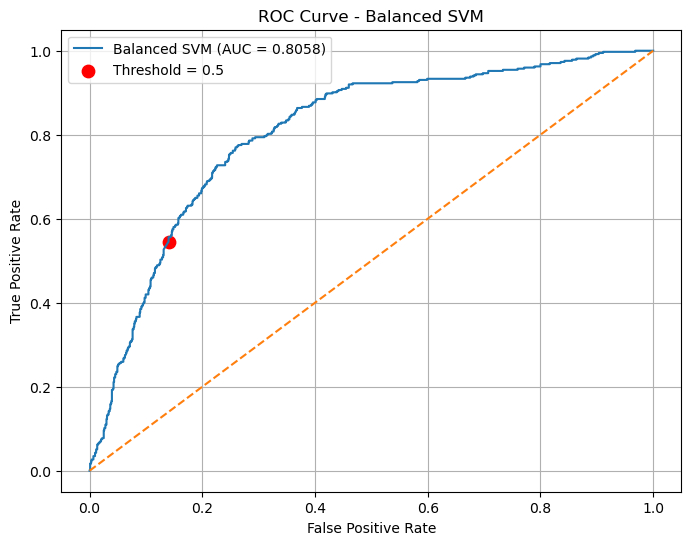

ROC-AUC Score: 0.8057932263814618
Threshold: 0.5


In [15]:
# YOUR CODE HERE — ROC or Precision-Recall curve

from sklearn.metrics import roc_curve, roc_auc_score

y_prob_balanced = svm_balanced.predict_proba(X_test_s)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_balanced
)

roc_auc = roc_auc_score(
    y_test,
    y_prob_balanced
)

threshold_index = np.argmin(np.abs(thresholds - 0.5))

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Balanced SVM (AUC = {roc_auc:.4f})'
)

plt.scatter(
    fpr[threshold_index],
    tpr[threshold_index],
    color='red',
    s=80,
    label='Threshold = 0.5'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Balanced SVM')

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)
print("Threshold:", thresholds[threshold_index])

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* When I switched from normal SVM to balanced SVM, precision decreased from 59.39% to 51.52%, while recall increased from 52.41% to 77.01%. This represents a decrease of 7.87 percentage points in precision and an increase of 24.60 percentage points in recall. The F1-score also improved from 55.68% to 61.74%. Therefore, balanced SVM became more effective at identifying actual churners.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* In my opinion, missing an actual churner can be more costly because the company loses a customer and potentially their future revenue. A false positive may result in unnecessary retention offers, but the customer remains with the company. Therefore, I would recommend Balanced SVM because it achieved 77.01% recall and 61.74% F1-score. It also reduced false negatives from 178 to 86, allowing the company to identify more customers at risk of leaving.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I obtained probability-like scores using the predict_proba() method of SVC. To enable this functionality, I set probability=True when creating the SVC model. These scores were then used with roc_curve() and roc_auc_score() to generate and evaluate the ROC curve.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [16]:
# YOUR CODE HERE — cross-model comparison table

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

comparison_models = {
    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=2
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Balanced SVM': svm_balanced
}

comparison_results = []

for name, model in comparison_models.items():

    if name == 'Balanced SVM':
        y_pred = imbalance_predictions['Balanced SVM']

    elif name in ['Logistic Regression', 'KNN']:
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    comparison_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        by='F1-Score',
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Balanced SVM,0.746629,0.515206,0.770053,0.617363
1,Logistic Regression,0.738822,0.505190,0.780749,0.613445
2,Random Forest,0.786373,0.623729,0.491979,0.550075
3,KNN,0.747339,0.525281,0.500000,0.512329
4,Decision Tree,0.741661,0.513889,0.494652,0.504087


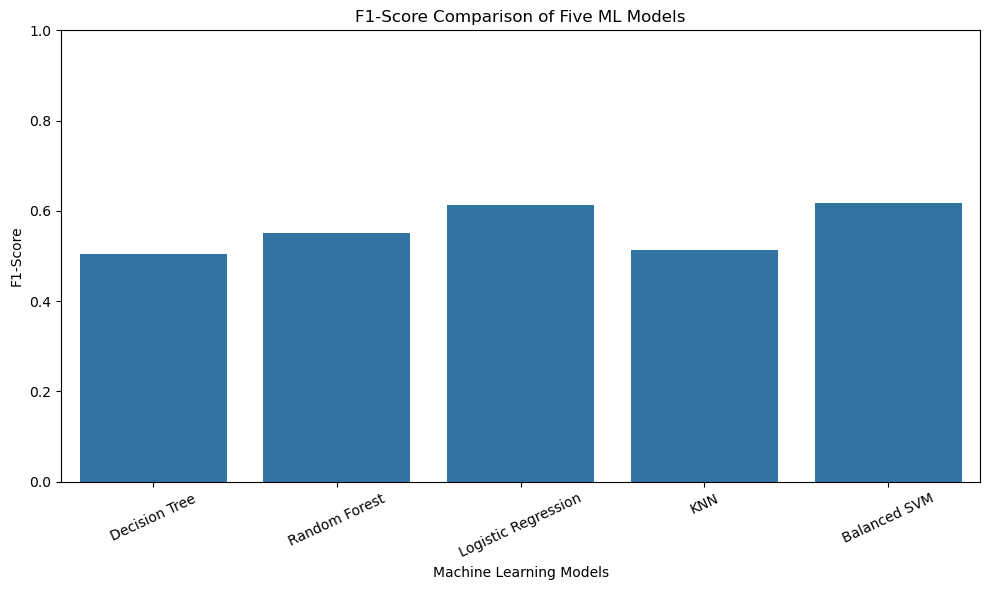

In [17]:
# YOUR CODE HERE — bar chart of F1-score across models

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='F1-Score'
)

plt.title('F1-Score Comparison of Five ML Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('F1-Score')

plt.xticks(rotation=25)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

The bar chart compares the F1-scores of five machine learning algorithms. Balanced SVM achieved the highest F1-score of 61.74%, followed closely by Logistic Regression at 61.34%. Random Forest achieved 55.01%, KNN achieved 51.23%, and Decision Tree achieved 50.41%. These results indicate that Balanced SVM and Logistic Regression provide better overall balance between precision and recall for predicting customer churn.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* Balanced SVM achieved the highest F1-score of 61.74%, while Logistic Regression achieved the highest recall of 78.07%. They are not the same model. Balanced SVM provides the best balance between precision and recall, whereas Logistic Regression identifies a slightly higher proportion of actual churners.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* Yes, the extra computational cost of SVM was worthwhile in this experiment because Balanced SVM achieved the highest F1-score of 61.74%, compared to 55.01% for Random Forest and 50.41% for Decision Tree. It also achieved 77.01% recall, making it more effective at identifying potential churners. However, Logistic Regression achieved slightly higher recall with a similar F1-score and may be a computationally simpler alternative.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I would recommend Balanced SVM for deployment because it achieved the highest F1-score of 61.74% and a recall of 77.01%. It correctly identified 288 actual churners out of 374, reducing the number of missed churners to 86. Although its precision was 51.52%, its improved ability to identify customers at risk of leaving makes it a suitable choice for a telecom company focused on customer retention.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [18]:
# YOUR CODE HERE — generate and save svm_predictions.csv

final_model = svm_balanced

final_predictions = final_model.predict(X_test_s)

final_probabilities = final_model.predict_proba(X_test_s)[:, 1]

predictions_df = pd.DataFrame({
    'true_label': y_test.values,
    'predicted_label': final_predictions,
    'predicted_score': final_probabilities
})

predictions_df.to_csv(
    'svm_predictions.csv',
    index=False
)

print("Predictions file saved successfully!")

display(predictions_df.head())

print("\nTotal Predictions:", len(predictions_df))
print("File Name: svm_predictions.csv")

Predictions file saved successfully!


,true_label,predicted_label,predicted_score
0,0,0,0.060593
1,0,1,0.604234
2,0,0,0.040179
3,0,0,0.254836
4,0,0,0.038981



Total Predictions: 1409
File Name: svm_predictions.csv


**Executive Summary**

In this lab, I implemented and evaluated Support Vector Machines using the Telco Customer Churn dataset. I compared Linear, RBF and Polynomial kernels and performed hyperparameter tuning using GridSearchCV. The best RBF configuration was C = 100 and gamma = 0.01, achieving a cross-validation F1-score of 58.77%. After comparing five machine learning algorithms, Balanced SVM achieved the highest F1-score of 61.74%, with 51.52% precision and 77.01% recall. I selected Balanced SVM as the final model because identifying actual churners is particularly important for customer retention. The main trade-off was reduced precision in exchange for improved recall, resulting in more false positives but fewer missed churners. One limitation of this analysis is that the model may not generalize perfectly to future customer data, and further feature engineering and validation could improve its performance.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* The most surprising result was that applying class_weight='balanced' significantly improved recall from 52.41% to 77.01% and increased the F1-score from 55.68% to 61.74%.

(b) If you had one more hour, what would you try next?

*Your answer:* I would experiment with SMOTE to address class imbalance, perform additional feature engineering, and explore a wider range of SVM hyperparameters to improve churn prediction performance.
